Bài 2. Dự đoán khả năng mắc bệnh dựa trên chỉ số BMI. Giả sử có một tập dữ liệu với các thông tin sau:
- BMI: Chỉ số khối cơ thể của bệnh nhân (Body Mass Index).
- Mắc bệnh: Nhãn mục tiêu là 1 nếu bệnh nhân mắc bệnh và 0 nếu không mắc bệnh.
Yêu cầu:
1. - Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn Mắc bệnh dựa trên mối liên hệ logic
(BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn).
2. - Sử dụng thư viện phù hợp để xây dựng mô hình hồi quy

In [12]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
bmi = load_diabetes()
x=bmi.data[:,[2]]
np.random.seed(0)
prob = 1 / (1 + np.exp(-40 * x[:, 0]))
y = np.random.binomial(1, prob)



3. - Huấn luyện mô hình
4. - Dự đoán xác xuất và nhãn mắc bệnh cho tập kiểm tra
5. - Trực quan hóa dữ liệu

Độ chính xác:  0.8651685393258427
Ma trận nhầm lẫn:  [[45  6]
 [ 6 32]]
Báo cáo phân loại:                precision    recall  f1-score   support

           0       0.88      0.88      0.88        51
           1       0.84      0.84      0.84        38

    accuracy                           0.87        89
   macro avg       0.86      0.86      0.86        89
weighted avg       0.87      0.87      0.87        89



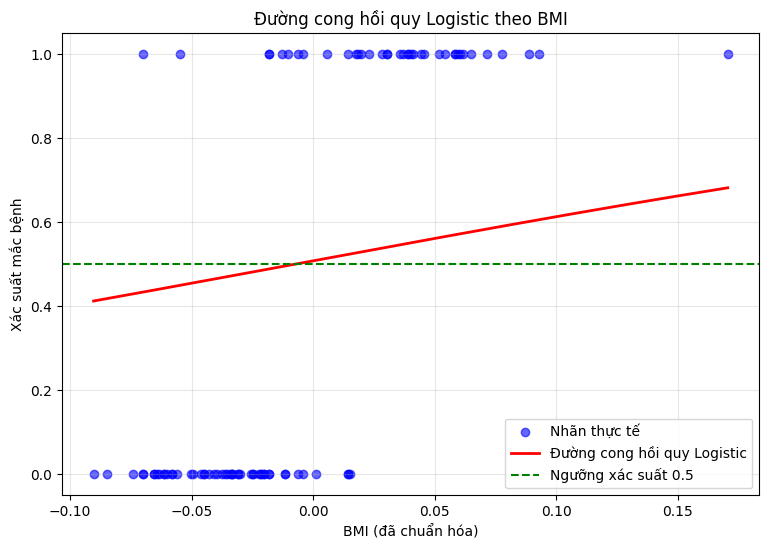

In [14]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
model = LogisticRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_rep = classification_report(y_test, y_pred)
print("Độ chính xác: ", accuracy)
print("Ma trận nhầm lẫn: ", conf_matrix)
print("Báo cáo phân loại: ", class_rep)

plt.scatter(x_test[:, 0], y_test, label="Nhãn thực tế")
plt.scatter(x_test[:, 0], y_pred, marker="x", label="Nhãn dự đoán")
plt.xlabel("BMI (đã chuẩn hóa)")
plt.ylabel("Mắc bệnh (0 hoặc 1)")
plt.legend()
plt.show()